<div align="center">

# Лабораторна робота № 7

## Нейронна класифікація зображень у TensorFlow

*Дисципліна «Інтелектуальний аналіз даних»*

</div>

<br>

**Мета роботи:** Навчитися подавати зображення й мітки класів для Keras, узгоджувати вихідний шар із функцією втрат, порівнювати моделі за validation та пояснювати конкретні помилки класифікації.

<br>

<div align="center">

Студентка: Сабадаш Анастасія  
Група: МІТ-31  
Варіант: 2  

</div>

## 1. Підготуйте дані та перевірте мітки

TensorFlow: 2.21.0
scikit-learn: 1.9.1
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 22s 1us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Форми вибірок:
  Train: (48000, 28, 28), мітки: (48000,)
  Validation: (12000, 28, 28), мітки: (12000,)
  Test: (10000, 28, 28), мітки: (10000,)

Тип даних (dtype): uint8
Мінімум/Максимум пікселів: 0 / 255
Мінімум/Максимум міток: 0 / 9


,Клас (цифра),Назва,Кількість об'єктів
0,0,Футболка або топ,4800
1,1,Штани,4800
2,2,Светр,4800
3,3,Сукня,4800
4,4,Пальто,4800
5,5,Сандалі,4800
6,6,Сорочка,4800
7,7,Кросівки,4800
8,8,Сумка,4800
9,9,Черевики,4800


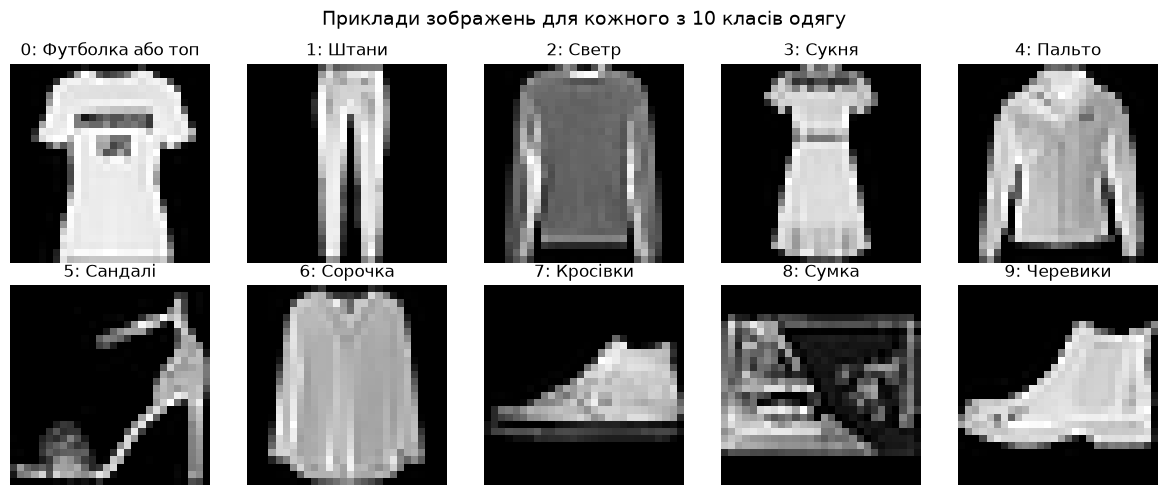

In [ ]:
from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

ARTIFACTS = Path('Lab7/artifacts')
ARTIFACTS.mkdir(parents=True, exist_ok=True)

print('TensorFlow:', tf.__version__)
print('scikit-learn:', sklearn.__version__)

# Завантаження даних та перевірка міток
(x_dev, y_dev), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "Футболка або топ", "Штани", "Светр", "Сукня", 
    "Пальто", "Сандалі", "Сорочка", "Кросівки", "Сумка", "Черевики"
]

x_train, x_val, y_train, y_val = train_test_split(
    x_dev, y_dev, test_size=0.20, stratify=y_dev, random_state=SEED
)

print(f"Форми вибірок:")
print(f"  Train: {x_train.shape}, мітки: {y_train.shape}")
print(f"  Validation: {x_val.shape}, мітки: {y_val.shape}")
print(f"  Test: {x_test.shape}, мітки: {y_test.shape}")

# Перевірка типів та діапазонів пікселів і міток
print(f"\nТип даних (dtype): {x_train.dtype}")
print(f"Мінімум/Максимум пікселів: {x_train.min()} / {x_train.max()}")
print(f"Мінімум/Максимум міток: {y_train.min()} / {y_train.max()}")

# Кількість об'єктів кожного класу у навчальній вибірці
unique_classes, counts = np.unique(y_train, return_counts=True)
class_counts_df = pd.DataFrame({
    'Клас (цифра)': unique_classes,
    'Назва': [class_names[i] for i in unique_classes],
    'Кількість об\'єктів': counts
})
display(class_counts_df)

# Перевірки за допомогою assert згідно з умовами
assert x_train.shape[1:] == (28, 28), "Вхідні дані повинні мати форму (N, 28, 28)"
assert y_train.ndim == 1, "Мітки повинні бути одновимірним масивом (N,)"
assert x_train.min() >= 0 and x_train.max() <= 255, "Значення пікселів мають бути в діапазоні 0–255"
assert y_train.min() >= 0 and y_train.max() <= 9, "Мітки повинні бути в діапазоні 0–9"

# Побудова сітки з 10 зображень — по одному на клас
plt.figure(figsize=(12, 5))
for i in range(10):
    # Знаходимо індекс першого входження класу i
    idx = np.where(y_train == i)[0][0]
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[idx], cmap='gray')
    plt.title(f"{i}: {class_names[i]}")
    plt.axis('off')

plt.suptitle("Приклади зображень для кожного з 10 класів одягу", fontsize=14)
plt.tight_layout()
plt.show()

## 2. Задайте єдиний спосіб підготовки

In [2]:
x_train = x_train.astype("float32")
x_val = x_val.astype("float32")
x_test = x_test.astype("float32")

assert x_train.shape[1:] == (28, 28), "Вхідні дані повинні мати форму (N, 28, 28)"
assert np.isfinite(x_train).all(), "Дані містять нескінченні або NaN значення"
assert set(np.unique(y_train)) == set(range(10)), "Мітки повинні охоплювати всі 10 класів (0-9)"

print("Перевірки для єдиного способу підготовки пройдені успішно!")
print(f"Форма x_train: {x_train.shape}, dtype: {x_train.dtype}")
print(f"Діапазон пікселів (залишено 0-255 для Rescaling всередині моделі): {x_train.min()} – {x_train.max()}")

Перевірки для єдиного способу підготовки пройдені успішно!
Форма x_train: (48000, 28, 28), dtype: float32
Діапазон пікселів (залишено 0-255 для Rescaling всередині моделі): 0.0 – 255.0


## 3. Побудуйте baseline та базову нейромережу

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

x_train_flat = x_train.reshape(len(x_train), -1)
x_val_flat = x_val.reshape(len(x_val), -1)
x_test_flat = x_test.reshape(len(x_test), -1)

# Навчання DummyClassifier
dummy_clf = DummyClassifier(strategy="most_frequent", random_state=SEED)
dummy_clf.fit(x_train_flat, y_train)

# Прогнози та метрики для baseline на валідації
dummy_preds_val = dummy_clf.predict(x_val_flat)
dummy_acc = accuracy_score(y_val, dummy_preds_val)
dummy_prec, dummy_rec, dummy_f1, _ = precision_recall_fscore_support(
    y_val, dummy_preds_val, average='macro', zero_division=0
)

print("Baseline (DummyClassifier: most_frequent)")
print(f"Validation Accuracy: {dummy_acc:.4f}")
print(f"Validation Macro-F1: {dummy_f1:.4f}\n")


# Побудова базової нейромережі
model_base = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Rescaling(1./255),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model_base.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
)

print("Архітектура базової нейромережі (NN_base)")
model_base.summary()

Baseline (DummyClassifier: most_frequent)
Validation Accuracy: 0.1000
Validation Macro-F1: 0.0182

Архітектура базової нейромережі (NN_base)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Навчіть моделі та виконайте індивідуальний варіант (№2)

Навчання базової нейромережі (NN_base)
NN_base: всього епох — 16, найкраща епоха — 12
Навчання варіативної нейромережі (NN_variant: 256 нейронів)
NN_variant: всього епох — 14, найкраща епоха — 10


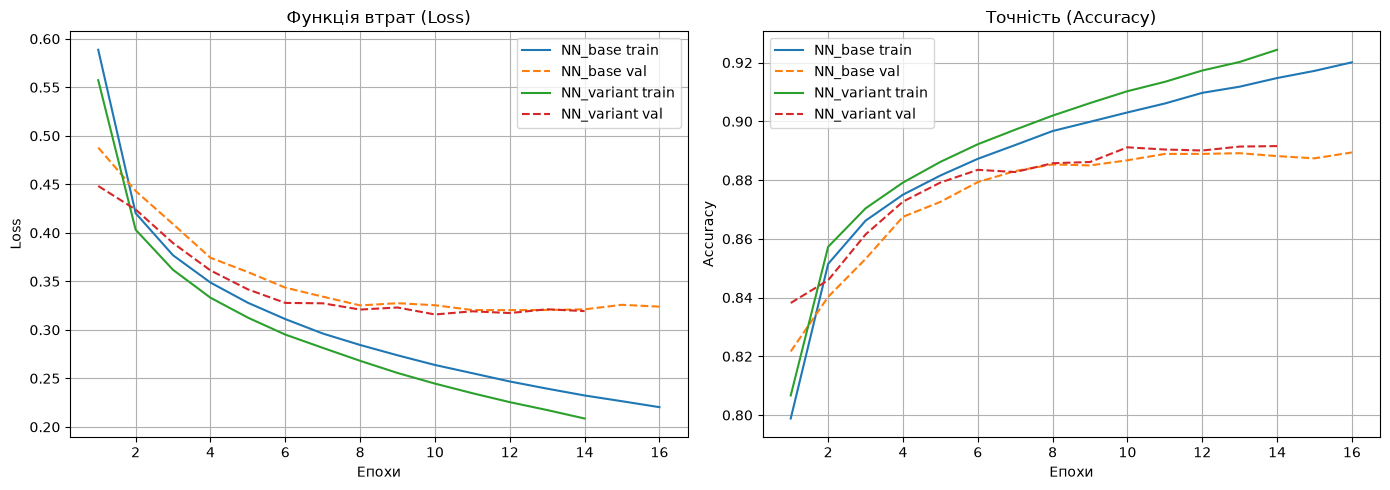

In [6]:
EPOCHS = 30
BATCH_SIZE = 128

run_infos = {}
histories = {}

# Навчання базової моделі (NN_base)
print("Навчання базової нейромережі (NN_base)")
keras.utils.set_random_seed(SEED)

model_base = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Rescaling(1./255),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model_base.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
)

checkpoint_base = ARTIFACTS / "base_best.keras"
callbacks_base = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(str(checkpoint_base), monitor="val_loss", save_best_only=True),
]

history_base = model_base.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks_base,
    verbose=0
)

model_base = keras.models.load_model(checkpoint_base)
histories['NN_base'] = history_base.history
run_infos['NN_base'] = {
    'epochs_run': len(history_base.history['loss']),
    'best_epoch': int(np.argmin(history_base.history['val_loss'])) + 1
}
print(f"NN_base: всього епох — {run_infos['NN_base']['epochs_run']}, найкраща епоха — {run_infos['NN_base']['best_epoch']}")


print("Навчання варіативної нейромережі (NN_variant: 256 нейронів)")
keras.utils.set_random_seed(SEED)

model_variant = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Rescaling(1./255),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model_variant.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
)

checkpoint_variant = ARTIFACTS / "variant_best.keras"
callbacks_variant = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(str(checkpoint_variant), monitor="val_loss", save_best_only=True),
]

history_variant = model_variant.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks_variant,
    verbose=0
)

model_variant = keras.models.load_model(checkpoint_variant)
histories['NN_variant'] = history_variant.history
run_infos['NN_variant'] = {
    'epochs_run': len(history_variant.history['loss']),
    'best_epoch': int(np.argmin(history_variant.history['val_loss'])) + 1
}
print(f"NN_variant: всього епох — {run_infos['NN_variant']['epochs_run']}, найкраща епоха — {run_infos['NN_variant']['best_epoch']}")


# Побудова графіків loss/val_loss та accuracy/val_accuracy для обох мереж
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, history in histories.items():
    epochs_range = np.arange(1, len(history['loss']) + 1)
    
    # Графік Loss
    axes[0].plot(epochs_range, history['loss'], label=f'{name} train')
    axes[0].plot(epochs_range, history['val_loss'], linestyle='--', label=f'{name} val')
    
    # Графік Accuracy
    axes[1].plot(epochs_range, history['accuracy'], label=f'{name} train')
    axes[1].plot(epochs_range, history['val_accuracy'], linestyle='--', label=f'{name} val')

axes[0].set_title('Функція втрат (Loss)')
axes[0].set_xlabel('Епохи')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

axes[1].set_title('Точність (Accuracy)')
axes[1].set_xlabel('Епохи')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 5. Перевірте формати міток на тих самих прогнозах

In [8]:
checkpoint_path = ARTIFACTS / "variant_best.keras" if (ARTIFACTS / "variant_best.keras").exists() else ARTIFACTS / "base_best.keras"
best_model_loaded = keras.models.load_model(checkpoint_path)

p_val = best_model_loaded(x_val[:5], training=False).numpy()

y_onehot = keras.utils.to_categorical(y_val[:5], num_classes=10)
a = keras.losses.SparseCategoricalCrossentropy()(y_val[:5], p_val)
b = keras.losses.CategoricalCrossentropy()(y_onehot, p_val)
np.testing.assert_allclose(a.numpy(), b.numpy(), rtol=1e-5)

print("Перевірка форматів міток пройдена успішно!")
print("Sparse loss:", a.numpy())
print("Categorical loss:", b.numpy())

Перевірка форматів міток пройдена успішно!
Sparse loss: 0.09903287
Categorical loss: 0.099032626


## 6. Оберіть нейромережу та перевірте результат

In [9]:
from sklearn.metrics import accuracy_score, f1_score

def classification_metrics(y, probabilities):
    labels = probabilities.argmax(axis=1)
    return {
        "cross_entropy": float(keras.losses.SparseCategoricalCrossentropy()(y, probabilities).numpy()),
        "accuracy": accuracy_score(y, labels),
        "macro_f1": f1_score(y, labels, average="macro", zero_division=0),
    }

model_base_loaded = keras.models.load_model(ARTIFACTS / "base_best.keras")
model_variant_loaded = keras.models.load_model(ARTIFACTS / "variant_best.keras")

# Прогнози на валідації
val_probs_base = model_base_loaded.predict(x_val, batch_size=256, verbose=0)
val_probs_variant = model_variant_loaded.predict(x_val, batch_size=256, verbose=0)

# Перевірка форми та діапазонів
assert val_probs_base.shape == (len(x_val), 10), "Форма ймовірностей має бути (N, 10)"
assert np.isfinite(val_probs_base).all(), "Ймовірності містять нескінченні або NaN значення"
assert (val_probs_base >= 0).all() and (val_probs_base <= 1).all(), "Ймовірності мають бути в діапазоні 0–1"
assert np.allclose(val_probs_base.sum(axis=1), 1.0, atol=1e-5), "Сума ймовірностей кожного рядка має бути близько 1"

metrics_base = classification_metrics(y_val, val_probs_base)
metrics_variant = classification_metrics(y_val, val_probs_variant)

print("Метрики NN_base на validation:", metrics_base)
print("Метрики NN_variant на validation:", metrics_variant)

if metrics_variant["cross_entropy"] < metrics_base["cross_entropy"]:
    best_nn_name = "NN_variant"
    best_nn_model = model_variant_loaded
else:
    best_nn_name = "NN_base"
    best_nn_model = model_base_loaded

print(f"\nОбрана нейромережа за крос-ентропією: {best_nn_name}")

# Прогнози та метрики на тесті для нейромереж
test_probs_base = model_base_loaded.predict(x_test, batch_size=256, verbose=0)
test_probs_variant = model_variant_loaded.predict(x_test, batch_size=256, verbose=0)

test_metrics_base = classification_metrics(y_test, test_probs_base)
test_metrics_variant = classification_metrics(y_test, test_probs_variant)

dummy_test_preds = dummy_clf.predict(x_test_flat)
dummy_test_acc = accuracy_score(y_test, dummy_test_preds)
dummy_test_f1 = f1_score(y_test, dummy_test_preds, average="macro", zero_division=0)

comparison_data = [
    {
        "model": "Dummy",
        "val_cross_entropy": None,
        "val_accuracy": dummy_acc,
        "val_macro_f1": dummy_f1,
        "test_cross_entropy": None,
        "test_accuracy": dummy_test_acc,
        "test_macro_f1": dummy_test_f1,
        "epochs_run": None
    },
    {
        "model": "NN_base",
        "val_cross_entropy": metrics_base["cross_entropy"],
        "val_accuracy": metrics_base["accuracy"],
        "val_macro_f1": metrics_base["macro_f1"],
        "test_cross_entropy": test_metrics_base["cross_entropy"],
        "test_accuracy": test_metrics_base["accuracy"],
        "test_macro_f1": test_metrics_base["macro_f1"],
        "epochs_run": run_infos["NN_base"]["epochs_run"]
    },
    {
        "model": "NN_variant",
        "val_cross_entropy": metrics_variant["cross_entropy"],
        "val_accuracy": metrics_variant["accuracy"],
        "val_macro_f1": metrics_variant["macro_f1"],
        "test_cross_entropy": test_metrics_variant["cross_entropy"],
        "test_accuracy": test_metrics_variant["accuracy"],
        "test_macro_f1": test_metrics_variant["macro_f1"],
        "epochs_run": run_infos["NN_variant"]["epochs_run"]
    }
]

model_comparison_df = pd.DataFrame(comparison_data).set_index("model")
display(model_comparison_df.round(4))

model_comparison_df.to_csv(ARTIFACTS / "model_comparison.csv", index_label="model")
print("\nТаблицю успішно збережено у файл ARTIFACTS/model_comparison.csv")

Метрики NN_base на validation: {'cross_entropy': 0.31974053382873535, 'accuracy': 0.8889166666666667, 'macro_f1': 0.889825908507204}
Метрики NN_variant на validation: {'cross_entropy': 0.31511321663856506, 'accuracy': 0.8911666666666667, 'macro_f1': 0.8914742834071101}

Обрана нейромережа за крос-ентропією: NN_variant


,val_cross_entropy,val_accuracy,val_macro_f1,test_cross_entropy,test_accuracy,test_macro_f1,epochs_run
model,,,,,,,
Dummy,NaN,0.1000,0.0182,NaN,0.1000,0.0182,NaN
NN_base,0.3197,0.8889,0.8898,0.3478,0.8763,0.8771,16.0
NN_variant,0.3151,0.8912,0.8915,0.3450,0.8796,0.8798,14.0



Таблицю успішно збережено у файл ARTIFACTS/model_comparison.csv


## 7. Дослідіть конкретні помилки

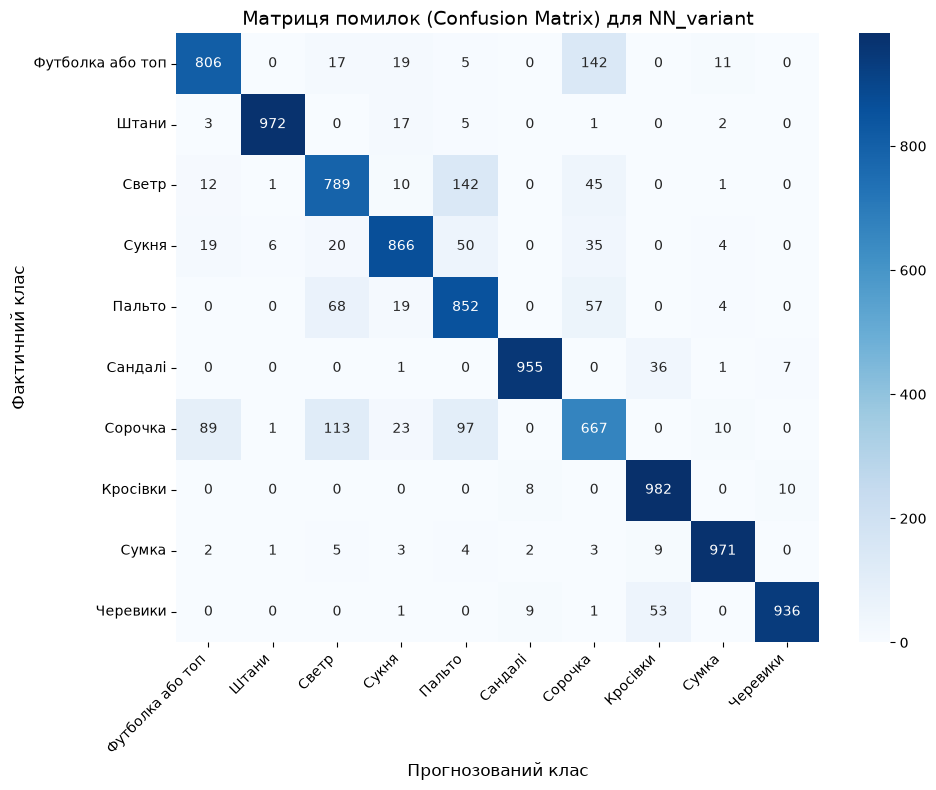


Детальний звіт класифікації (Classification Report):
                  precision    recall  f1-score   support

Футболка або топ       0.87      0.81      0.83      1000
           Штани       0.99      0.97      0.98      1000
           Светр       0.78      0.79      0.78      1000
           Сукня       0.90      0.87      0.88      1000
          Пальто       0.74      0.85      0.79      1000
         Сандалі       0.98      0.95      0.97      1000
         Сорочка       0.70      0.67      0.68      1000
        Кросівки       0.91      0.98      0.94      1000
           Сумка       0.97      0.97      0.97      1000
        Черевики       0.98      0.94      0.96      1000

        accuracy                           0.88     10000
       macro avg       0.88      0.88      0.88     10000
    weighted avg       0.88      0.88      0.88     10000


Знайдено помилок: 1204. Виводимо до 5 найвпевненіших:


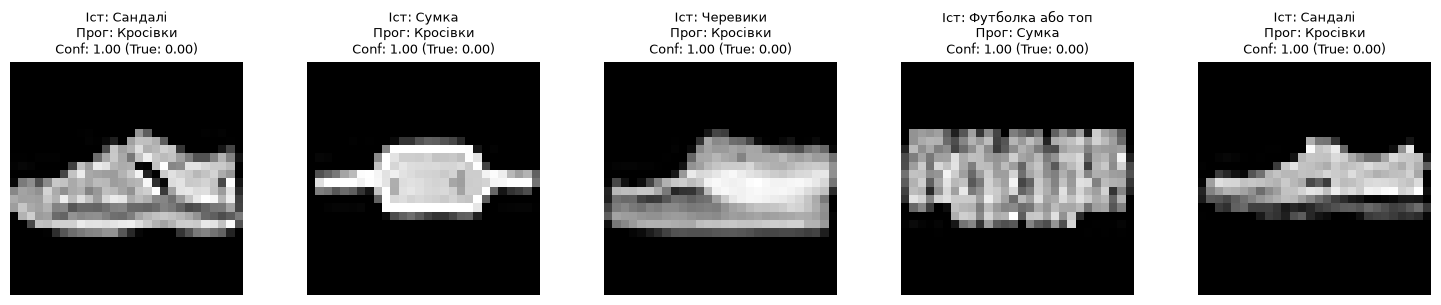

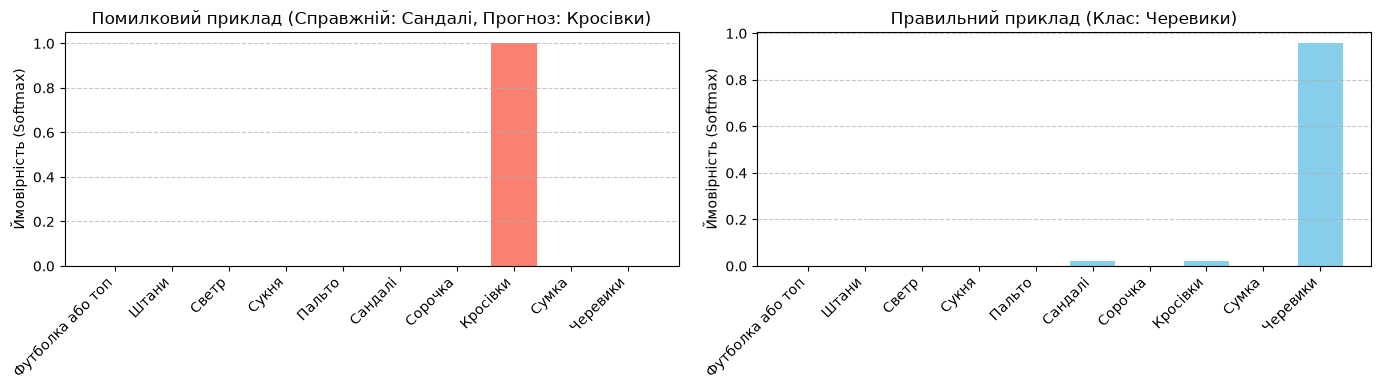

In [10]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

test_probabilities = best_nn_model.predict(x_test, batch_size=256, verbose=0)

pred = test_probabilities.argmax(axis=1)
confidence = test_probabilities.max(axis=1)

cm = confusion_matrix(y_test, pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Матриця помилок (Confusion Matrix) для {best_nn_name}', fontsize=14)
plt.xlabel('Прогнозований клас', fontsize=12)
plt.ylabel('Фактичний клас', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nДетальний звіт класифікації (Classification Report):")
print(classification_report(y_test, pred, target_names=class_names, zero_division=0))


# Пошук до 5 найвпевненіших помилок
wrong = np.flatnonzero(pred != y_test)
order = wrong[np.argsort(confidence[wrong])[::-1]]
show_ids = order[:5]

print(f"\nЗнайдено помилок: {len(wrong)}. Виводимо до 5 найвпевненіших:")

if len(show_ids) > 0:
    plt.figure(figsize=(15, 3))
    for i, idx in enumerate(show_ids):
        plt.subplot(1, len(show_ids), i + 1)
        plt.imshow(x_test[idx], cmap='gray')
        true_cls = class_names[y_test[idx]]
        pred_cls = class_names[pred[idx]]
        conf = confidence[idx]
        true_conf = test_probabilities[idx, y_test[idx]]
        plt.title(f"Іст: {true_cls}\nПрог: {pred_cls}\nConf: {conf:.2f} (True: {true_conf:.2f})", fontsize=9)
        plt.axis('off')
    plt.tight_layout()
    plt.show()


# Для одного помилкового та одного правильного прикладу побудуємо стовпчики всіх 10 оцінок
# Знаходимо індекс одного правильного і одного помилкового прикладу
correct_idx = np.flatnonzero(pred == y_test)[0]
wrong_idx = show_ids[0] if len(show_ids) > 0 else correct_idx

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Помилковий приклад
axes[0].bar(range(10), test_probabilities[wrong_idx], color='salmon')
axes[0].set_xticks(range(10))
axes[0].set_xticklabels(class_names, rotation=45, ha='right')
axes[0].set_title(f"Помилковий приклад (Справжній: {class_names[y_test[wrong_idx]]}, Прогноз: {class_names[pred[wrong_idx]]})")
axes[0].set_ylabel("Ймовірність (Softmax)")
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Правильний приклад
axes[1].bar(range(10), test_probabilities[correct_idx], color='skyblue')
axes[1].set_xticks(range(10))
axes[1].set_xticklabels(class_names, rotation=45, ha='right')
axes[1].set_title(f"Правильний приклад (Клас: {class_names[y_test[correct_idx]]})")
axes[1].set_ylabel("Ймовірність (Softmax)")
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## 8. Збережіть і перевірте прогноз після завантаження

In [12]:
# Зберігаємо обрану нейромережу
selected_model = best_nn_model  # Обрана раніше за validation нейромережа
selected_model.save(ARTIFACTS / "lab7_model.keras")

# Перевіряємо прогноз до та після збереження (завантаження)
probe = x_val[:3]
before = selected_model(probe, training=False).numpy()

restored = keras.models.load_model(ARTIFACTS / "lab7_model.keras")
after = restored(probe, training=False).numpy()

np.testing.assert_allclose(before, after, rtol=1e-5, atol=1e-6)
print("Перевірка відновлення пройдена успішно: прогнози до та після збереження ідентичні!")

# Записуємо метадані у metadata.json
metadata = {
    "class_names": class_names,
    "input_shape": [28, 28],
    "dtype": str(x_train.dtype),
    "input_scale": "0-255 (Rescaling всередині моделі)",
    "seed": SEED,
    "variant": 2,
    "selection_criterion": "lowest validation cross-entropy",
    "tensorflow_version": tf.__version__,
    "sklearn_version": sklearn.__version__
}

with open(ARTIFACTS / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)

print("Метадані успішно записано у файл ARTIFACTS/metadata.json")


single_image = x_val[0]
image_batch = np.expand_dims(single_image, axis=0)

probabilities_single = restored(image_batch, training=False).numpy()
predicted_class_idx = probabilities_single.argmax(axis=1)[0]
predicted_class_name = class_names[predicted_class_idx]
confidence_score = probabilities_single.max(axis=1)[0]

print("\nПриклад прогнозу для одного зображення:")
print("Прогнозований індекс класу:", predicted_class_idx)
print("Назва класу:", predicted_class_name)
print("Впевненість (confidence):", confidence_score)

Перевірка відновлення пройдена успішно: прогнози до та після збереження ідентичні!
Метадані успішно записано у файл ARTIFACTS/metadata.json

Приклад прогнозу для одного зображення:
Прогнозований індекс класу: 5
Назва класу: Сандалі
Впевненість (confidence): 0.9364853


**Висновок:** У ході лабораторної роботи успішно реалізовано пайплайн класифікації Fashion MNIST: налаштовано дані й бейзлайн (DummyClassifier), навчено базову нейромережу та варіативний варіант із колбеками, проведено порівняння за крос-ентропією, точністю та macro-F1, проаналізовано помилки й збережено найкращу модель разом із метаданими.